In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('diabetes_patients_10000_full.csv')

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [4]:
data.isnull().sum()

Patient_ID            0
Age                  14
Gender               40
Blood_Sugar_Level    53
Creatinine           56
BMI                  51
Urea                 51
Cholesterol          32
HbA1c                 0
Class                 0
dtype: int64

In [5]:
data.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [6]:
data.duplicated().sum()

np.int64(0)

In [7]:
data.drop('Patient_ID', axis=1, inplace=True)

In [8]:
data.head()

,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [9]:
data.describe()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [10]:
data.columns

Index(['Age', 'Gender', 'Blood_Sugar_Level', 'Creatinine', 'BMI', 'Urea',
       'Cholesterol', 'HbA1c', 'Class'],
      dtype='object')

In [12]:
num_cols = data.select_dtypes(include =['float64', 'int64']).columns
cat_cols = ['Gender']

In [13]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [ ]:
# imputing for the num cols using median strategy

num_imputer = SimpleImputer(strategy = 'median')
data[num_cols] = num_imputer.fit_transform(data[num_cols])

In [ ]:
# imputing for the categorical cols using most_frequent strategy

cat_imputer = SimpleImputer(strategy = 'most_frequent')
data[cat_cols] = cat_imputer.fit_transform(data[cat_cols])

In [ ]:
# encoding

data['Gender'] = data['Gender'].map({'Male': 1, 'Female': 0})
data['Class'] = data['Class'].map({'Diabetic': 1, 'Non-Diabetic': 0})


In [19]:
# Splitting

x = data.drop('Class', axis=1)
y = data['Class']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Scalling

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [ ]:
# Models & Metrics

models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(probability=True), 
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

from sklearn.metrics import accuracy_score, classification_report

for name, model in models.items():
    model.fit(x_train_scaled, y_train)
    
    y_pred = model.predict(x_test_scaled)
    
    acc = accuracy_score(y_test, y_pred)
    
    print(f"--- {name} ---")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))
    print("-" * 30)

--- Logistic Regression ---
Accuracy: 0.9700
              precision    recall  f1-score   support

           0       0.87      0.77      0.81       171
           1       0.98      0.99      0.98      1829

    accuracy                           0.97      2000
   macro avg       0.92      0.88      0.90      2000
weighted avg       0.97      0.97      0.97      2000

------------------------------
--- KNN ---
Accuracy: 0.9630
              precision    recall  f1-score   support

           0       0.84      0.70      0.76       171
           1       0.97      0.99      0.98      1829

    accuracy                           0.96      2000
   macro avg       0.91      0.84      0.87      2000
weighted avg       0.96      0.96      0.96      2000

------------------------------
--- Naive Bayes ---
Accuracy: 0.9855
              precision    recall  f1-score   support

           0       1.00      0.83      0.91       171
           1       0.98      1.00      0.99      1829

    accur

In [36]:
from sklearn.metrics import accuracy_score, classification_report

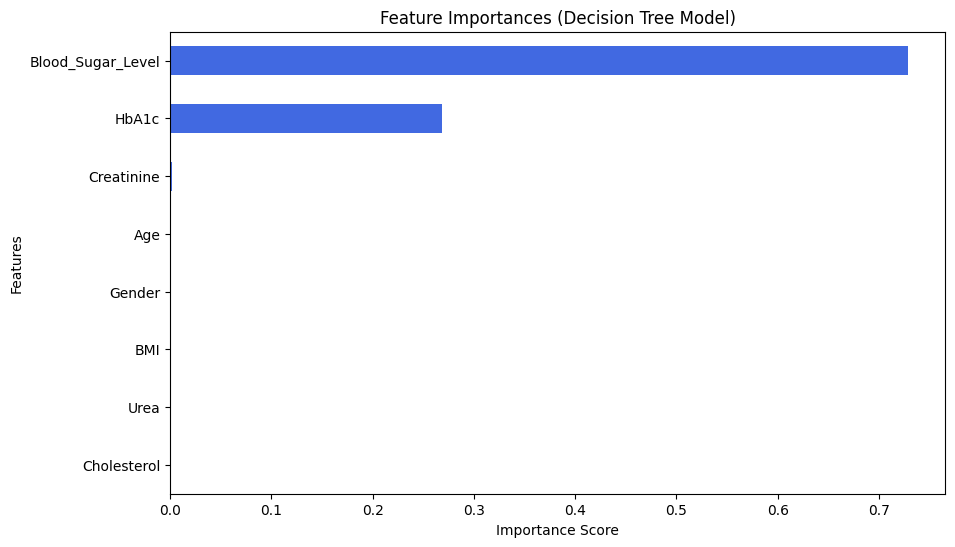

In [44]:
# Feature Importance

dt_model = models["Decision Tree"]

feat_importances = pd.Series(dt_model.feature_importances_, index=x.columns)

# Visualization
plt.figure(figsize=(10, 6))
feat_importances.nlargest(10).sort_values().plot(kind='barh', color='royalblue')
plt.title('Feature Importances (Decision Tree Model)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [40]:
# Grid Search

param_grid = {
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 20]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy'
)

In [42]:
grid_search.fit(x_train_scaled, y_train)

print("Best Parameters for Decision Tree:", grid_search.best_params_)
print(f"Best Grid Search Score (Accuracy): {grid_search.best_score_:.4f}")

Best Parameters for Decision Tree: {'max_depth': None, 'min_samples_split': 10}
Best Grid Search Score (Accuracy): 0.9998
